<div style="background-color:rgb(100, 110, 220); padding:10px;">

## Day 8: Time Series

### Dataset: temperature.csv

</div>

# 1. Data Preprocessing

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.seasonal import STL
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.metrics import mean_absolute_error, mean_squared_error


pd.options.display.float_format = '{:,.3f}'.format
plt.rcParams['figure.figsize'] = (12, 4)

## Understand the Data

**Why:** Before touching code, you must understand what you have — the model depends on it.

### Key Checks:

- **Inspect the structure:**  
  Is it univariate (one variable over time) or multivariate (several variables)?

- **Check the frequency:**  
  Daily, hourly, monthly, etc.

- **Identify the target variable:**  
  What are you trying to predict or model?

In [2]:
df = pd.read_csv("../Lecture_data/temperature.csv")
display(df.head())
df.shape

,Station Name,Measurement Timestamp,Air Temperature
0,63rd Street Weather Station,01/01/2016 12:00:00 AM,-2.800
1,Oak Street Weather Station,01/01/2016 12:00:00 AM,-2.300
2,Foster Weather Station,01/01/2016 12:00:00 AM,-3.670
3,63rd Street Weather Station,01/01/2016 01:00:00 AM,-3.400
4,Foster Weather Station,01/01/2016 01:00:00 AM,-4.560


(23686, 3)

In [3]:
df.groupby("Station Name").nunique()

,Measurement Timestamp,Air Temperature
Station Name,,
63rd Street Weather Station,8047,505
Foster Weather Station,8123,521
Oak Street Weather Station,7516,501


In [4]:
df.groupby("Station Name")["Air Temperature"].describe()

,count,mean,std,min,25%,50%,75%,max
Station Name,,,,,,,,
63rd Street Weather Station,"8,047.000",12.143,10.898,-19.500,3.400,12.900,21.700,33.600
Foster Weather Station,"8,123.000",11.254,10.946,-19.890,2.670,11.500,20.890,33.560
Oak Street Weather Station,"7,516.000",12.633,10.928,-17.900,4.100,13.300,22.200,34.000


## Parse timestamp and coerce numerics


In [5]:
FMT = "%m/%d/%Y %I:%M:%S %p"
df['Measurement Timestamp'] = pd.to_datetime(df['Measurement Timestamp'], format=FMT, errors='coerce')
df['Air Temperature'] = pd.to_numeric(df['Air Temperature'], errors='coerce') # ⚠️ ensure numeric

In [6]:
df.head()

,Station Name,Measurement Timestamp,Air Temperature
0,63rd Street Weather Station,2016-01-01 00:00:00,-2.800
1,Oak Street Weather Station,2016-01-01 00:00:00,-2.300
2,Foster Weather Station,2016-01-01 00:00:00,-3.670
3,63rd Street Weather Station,2016-01-01 01:00:00,-3.400
4,Foster Weather Station,2016-01-01 01:00:00,-4.560


In [7]:
STATION = "63rd Street Weather Station" 
df = df[df['Station Name'] == STATION].copy()
df = df.drop(columns=['Station Name'])  

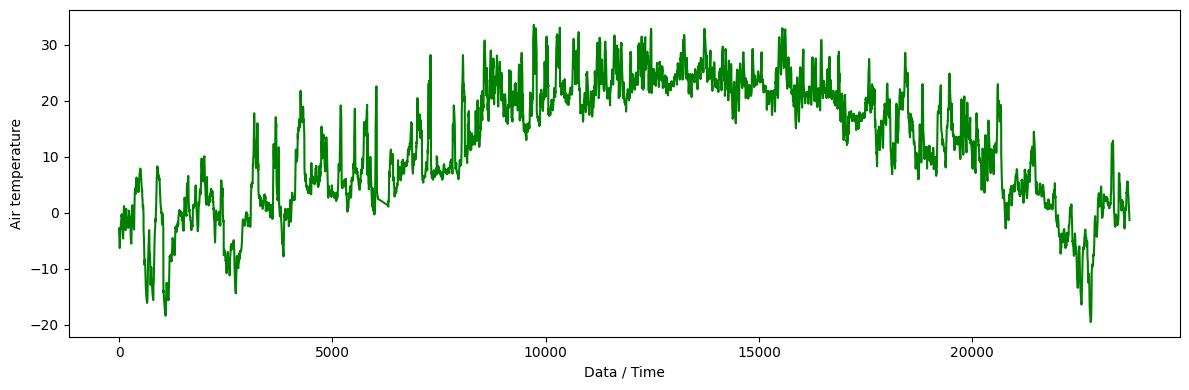

In [8]:
plt.plot(df['Air Temperature'], color='green')
plt.ylabel('Air temperature')
plt.xlabel('Data / Time')
plt.tight_layout()
plt.show()


## Sort, De‑duplicate 

In [9]:
#Sort by time
df = df.dropna(subset=['Measurement Timestamp']).sort_values('Measurement Timestamp')

# Keep the last duplicate as a reproducible convention; reliability needs metadata.
df = df.drop_duplicates(subset=['Measurement Timestamp'], keep='last')

# Set DateTime Index
df = df.set_index('Measurement Timestamp').sort_index()
print('After de-dup:', df.shape)

After de-dup: (8047, 1)


## Audit Frequency/Gaps

In [10]:
df["Air Temperature"].isna().sum()

0

In [11]:
# time gaps BEFORE enforcing a frequency
diffs = df.index.to_series().diff().dropna()

print(diffs.value_counts().head())
print("Most common interval:", diffs.mode()[0])


Measurement Timestamp
0 days 01:00:00    7897
0 days 02:00:00     117
0 days 03:00:00      11
0 days 08:00:00       3
0 days 13:00:00       2
Name: count, dtype: int64
Most common interval: 0 days 01:00:00


In [12]:
expected_frequency = pd.Timedelta('1h')
intervals = df.index.to_series().diff().dropna()
gap_runs = intervals[intervals > expected_frequency]
missing_hours = ((gap_runs / expected_frequency) - 1).sum()
print(f'{len(gap_runs)} gaps spanning {int(missing_hours)} missing hourly timestamps.')

149 gaps spanning 737 missing hourly timestamps.


In [13]:
df = df.asfreq('H')
print('Missing after asfreq:', int(df['Air Temperature'].isna().sum()))

Missing after asfreq: 737


## Temporal and Geographical Splitting
When working with datasets that have a temporal or geographical component, it’s essential to consider splitting the data in a way that reflects these aspects. This approach helps in better generalizing the model to unseen data.


<img src="https://upload.wikimedia.org/wikipedia/commons/8/85/Landslide_susceptibility_mapping_dataset_splitting.png" alt="Beautiful Landscape" width="1300">


### Why geographical splitting?
A held-out region tests transfer to a new location more directly than a random row split when nearby observations are related. It does not guarantee generalisation to every new region. Choose the split to resemble the intended use; temporal forecasting similarly needs a chronological holdout.

In [14]:
# Temporal split (last 20% as test)
split_idx = int(len(df) * 0.8)
train, test = df.iloc[:split_idx], df.iloc[split_idx:]


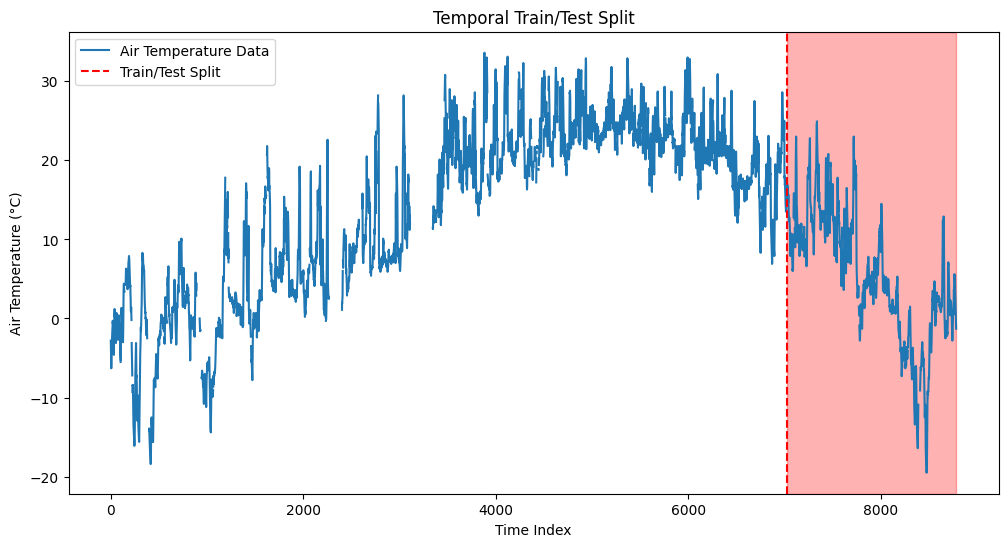

In [15]:
plt.figure(figsize=(12, 6))
plt.plot(df['Air Temperature'].values, label='Air Temperature Data')
plt.axvline(x=split_idx, color='r', linestyle='--', label='Train/Test Split')
plt.axvspan(split_idx, len(df), color='red', alpha=0.3)
plt.legend()
plt.title('Temporal Train/Test Split')
plt.xlabel('Time Index')
plt.ylabel('Air Temperature (°C)')
plt.show()

## Forward-fill missing training values
Forward filling uses past information only, but repeated values can distort autocorrelation. Inspect long gaps and compare alternative missing-data approaches for a final model.

Keep missing **test targets** missing: they are not observed truth and must not contribute to forecast error.

In [16]:
train_f = train['Air Temperature'].ffill().dropna()
test_observed = test['Air Temperature'].copy()
observed_mask = test_observed.notna()
print('Training length:', len(train_f))
print('Observed test targets:', observed_mask.sum(), '/', len(test_observed))

Training length: 7027
Observed test targets: 1716 / 1757


# Model selection
## 1. Classical Statistical Models

- **ARMA (Autoregressive Moving Average)**  
  For stationary time series. Combines AR and MA components.

- **ARIMA (Autoregressive Integrated Moving Average)**  
  Adds differencing to handle non-stationary data.  
  **Model:** ARIMA(p, d, q)

- **SARIMA (Seasonal ARIMA)**  
  Extends ARIMA to handle seasonality.  
  **Model:** SARIMA(p, d, q)(P, D, Q, s)

- **ARIMAX / SARIMAX**  
  Includes exogenous variables (external predictors).  
  Useful when other time series influence the target.

- **VAR (Vector Autoregression)**  
  Multivariate time series model.  
  Models multiple interdependent time series.

---

##  2. Exponential Smoothing Models

- **Simple Exponential Smoothing**  
  For data with no trend or seasonality.

- **Holt’s Linear Trend Method**  
  Adds trend component.

- **Holt-Winters (Triple Exponential Smoothing)**  
  Adds seasonality.

---

##  3. Machine Learning Models

- **Regression Models**  
  Use lag features, rolling stats, and time-based features.  
  **Algorithms:** Linear Regression, Random Forest, XGBoost

- **Support Vector Regression (SVR)**  
  Good for non-linear patterns.

- **K-Nearest Neighbors (KNN)**  
  Forecasts based on similar historical patterns.

---

##  4. Deep Learning Models

- **RNN (Recurrent Neural Networks)**  
  Designed for sequential data. Can capture temporal dependencies.

- **LSTM (Long Short-Term Memory)**  
  Handles long-term dependencies better than RNN.

- **GRU (Gated Recurrent Unit)**  
  Similar to LSTM but simpler.

- **Temporal Convolutional Networks (TCN)**  
  Use convolutions instead of recurrence.

---

##  5. Hybrid and Ensemble Models

Combine statistical and ML models.  
**Examples:** ARIMA + XGBoost, LSTM + SARIMA

---

##  6. Prophet (by Meta)

A flexible model for time series forecasting.  
Handles missing data, seasonality, holidays, and trend changes.


## Time Series Basics

A **time series** is an ordered sequence of observations over time:

$$
\{y_t\}_{t=1}^{T}
$$
Most real-world time series can be expressed as a combination of interpretable components:

### Additive Model:
$$
y_t = T_t + S_t + C_t + e_t
$$

### Multiplicative Model:
$$
y_t = T_t \times S_t \times C_t \times e_t
$$
or some prefer: 

$$
\ln(y_t) = \ln(T_t) + \ln(S_t) + \ln(C_t) + \ln(e_t)
$$


Where:

- **$T_t$** — **Trend**: long-term growth or decline over time.
- **$S_t$** — **Seasonality**: regular, repeating patterns (daily, weekly, annual, etc.).
- **$C_t$** — **Cycle**: slower, irregular oscillations (e.g., business cycles).
- **$e_t$** — **Irregular / Noise**: unpredictable random variation.

##  Trend and Stationarity ($ T_t $)

The **trend** represents long-term movement in the mean of the series — upward, downward, or curved.

---
##  Stationarity
Weak stationarity concerns the distribution over time, not the absence of all temporal structure. A stationary process can have autocorrelation, including seasonal lag dependence. A changing deterministic mean or variance violates weak stationarity.

A (weakly) **stationary process** satisfies the following conditions:

- **Constant Mean:**
  $$
  E[y_t] = \mu
  $$

- **Constant Variance:**
  $$
  \text{Var}(y_t) = \sigma^2
  $$

- **Autocovariance Depends Only on Lag:**
  $$
  \text{Cov}(y_t, y_{t+h}) = \gamma(h)
  $$
  (i.e., depends only on the lag \( h \), not on time \( t \))

This means the series:

- Fluctuates around a **stable mean**
- Has **constant variability**
- Maintains a **consistent autocorrelation structure** over time

### Checks for Stationarity
There are many methods to check whether a time series (direct observations, residuals, otherwise) is stationary or non-stationary.

- **Plotting the series:**  
  Visually inspect for upward or downward drift.

- **Rolling statistics:**  
  Rolling mean or variance changing over time.

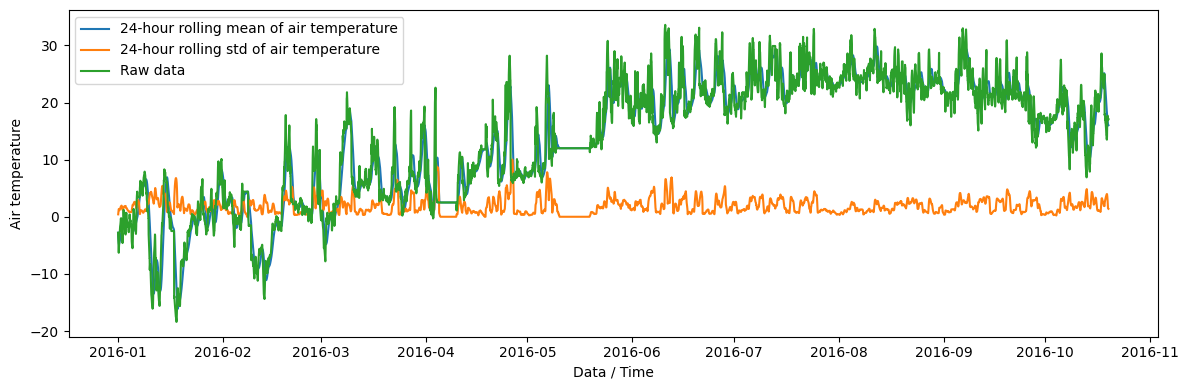

In [17]:
rolling_temp = train_f.rolling(window='1d').mean()
rolling_std = train_f.rolling(window='1d').std()

plt.plot(rolling_temp, label='24-hour rolling mean of air temperature')
plt.plot(rolling_std, label='24-hour rolling std of air temperature')
plt.plot(train_f, label='Raw data')
plt.ylabel('Air temperature')
plt.xlabel('Data / Time')
plt.legend()
plt.tight_layout()
plt.show()

### Augmented Dickey-Fuller (ADF) test
The null hypothesis is a unit root under the specified deterministic terms and lag model.

- A small p-value is evidence against that null; it does not imply no autocorrelation.
- Failure to reject is not proof of a unit root.
- Stationarity also concerns variance and covariance over time. Combine the test with plots, domain knowledge and diagnostics.

Here the default test includes a constant. A deterministic trend, seasonal roots or structural breaks may require different diagnostics.

In [18]:
from statsmodels.tsa.stattools import adfuller

adf_stats, pvalue, *_ = adfuller(train_f)

In [19]:
print('ADF statistic:', adf_stats)
print('p-value:', pvalue)

ADF statistic: -3.501597162189993
p-value: 0.007946170171979313


Interpret the p-value using the stated null. Does the result agree with the training-series plot? Rejecting a unit root does not make seasonality, changing variance or residual dependence disappear.

ARMA assumes stationary dependence. Other model families can represent non-stationarity directly; it is not a requirement of every statistical model. For ARMA, choose a justified transformation or explicitly model the changing structure.

###  Trend Extraction Methods

| **Method**                         | **Purpose**                                                    | **Formula / Description**                                                                 |
|-----------------------------------|----------------------------------------------------------------|--------------------------------------------------------------------------------------------|
| **Differencing**                  | Removes *stochastic* (random walk) trend                       | $$\nabla y_t = y_t - y_{t-1}$$ — Choose the differencing order from the stochastic specification and training diagnostics; avoid over-differencing.     |
| **Hodrick–Prescott (HP) Filter**  | Smooths out short-term fluctuations to extract a smooth trend. | $$\min_{\tau_t} \sum (y_t - \tau_t)^2 + \lambda \sum (\Delta^2 \tau_t)^2$$                 |
| **Deterministic Trend Regression**| Fit and subtract a time function (linear, quadratic, etc.)     | $$y_t = \alpha + \beta t + \varepsilon_t \Rightarrow \hat{\varepsilon}_t = y_t - (\alpha + \beta t)$$ |
| **Moving Average Smoothing**      | Approximate slow-moving trend using local averages.            | $$\hat{T}_t = \frac{1}{m} \sum_{i=-k}^{k} y_{t+i}$$                                         |

A polynomial trend can be removed by suitable differencing, but this does not justify repeatedly differencing every series. Over-differencing adds unnecessary dependence. Centred moving averages use future values and suit retrospective description, not causal forecasting features.

A constant mean and variance are necessary but not sufficient for weak stationarity: covariance must depend only on lag, not calendar time. Inspect the transformed series and its dependence before fitting a stationary model.

## Seasonality

###  What is seasonality?

Seasonality $ S_t $ is a repeating pattern that occurs at a known, fixed frequency $s $.

###  Detecting seasonality

| Method                    | Description                                               |
|---------------------------|-----------------------------------------------------------|
| Plot the series           | Repeating cycles at regular intervals.                    |
| Seasonal subseries plots  | Compare monthly/quarterly means visually.                 |
| Autocorrelation (ACF)     | Spikes at lags equal to the seasonal period (e.g., 12 for monthly data). |
| Periodogram / Spectrum    | Peaks at dominant frequencies.                            |

---

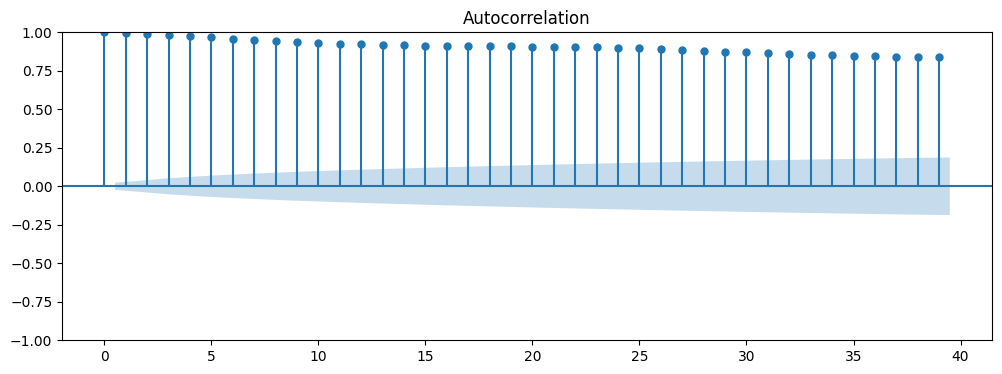

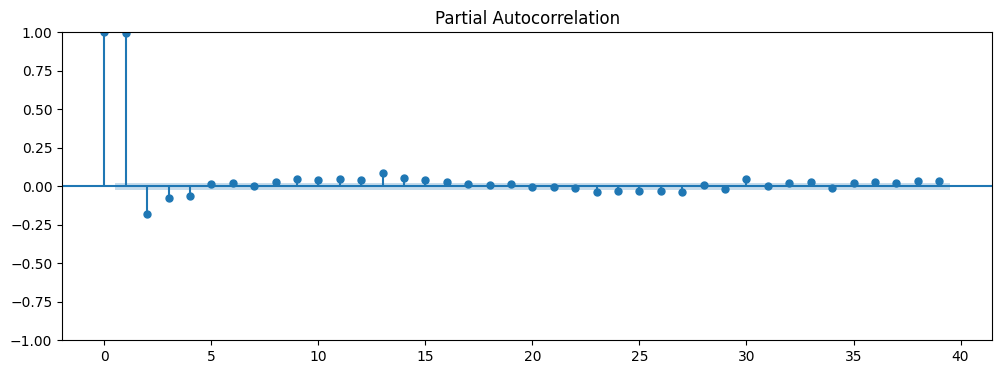

In [20]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plot_acf(train_f)
plot_pacf(train_f)
plt.show()

###  Deseasonalizing methods

| Method                   | Description                                               | Formula / Notes                                                                 |
|--------------------------|-----------------------------------------------------------|----------------------------------------------------------------------------------|
| Classical decomposition  | Compute average seasonal indices and subtract/divide.     | $S_t = \text{mean of same month/quarter} $                                   |
| STL decomposition        | Robust decomposition into $ T_t + S_t + R_t $, handles changing seasonality. | `statsmodels.tsa.seasonal.STL`                                                  |
| Seasonal differencing    | Removes stochastic seasonal patterns.                     | $ \nabla_s y_t = y_t - y_{t-s} $                                              |
| Fourier terms            | Use sine/cosine functions as seasonal regressors.         | $ \sin(2\pi kt/s), \cos(2\pi kt/s) $                                           |

---

After removing trend and seasonality:

$$
w_t = y_t - \hat{T}_t - \hat{S}_t
$$

or via differencing:

$$
w_t = (1 - B^s)^D(1 - B)^d y_t
$$

Check whether $w_t$ is approximately stationary; the transformation alone does not guarantee this.

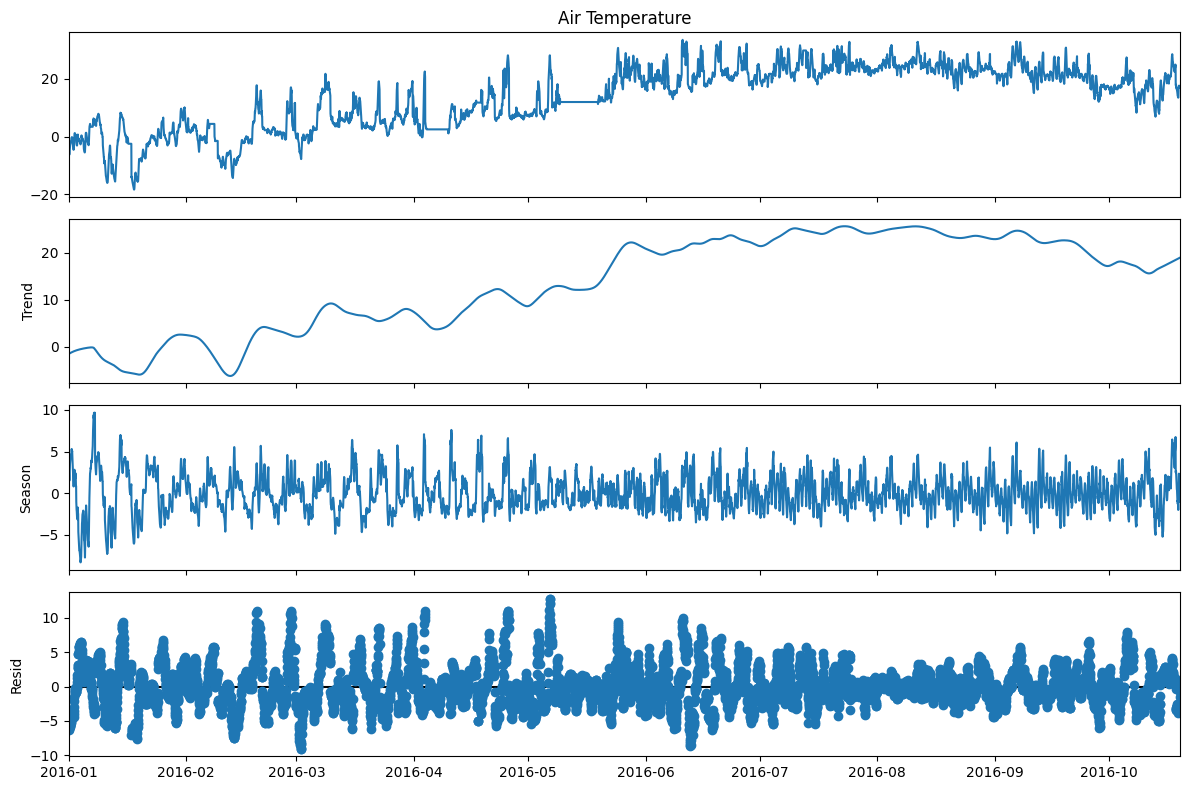

In [21]:
from statsmodels.tsa.seasonal import STL

stl = STL(train_f, period=24*7).fit()
stl.plot().set_size_inches(12, 8)
plt.tight_layout()
# plt.xticks(rotation=45)
plt.show()

## Modelling the remainder
After removing estimated trend and seasonal components, check the remainder's mean, variance and autocorrelation. ARMA is a candidate if stationary dependence is plausible. STL is a descriptive decomposition here; its training fit does not itself forecast future trend and seasonality.

##  ARMA model

$$
w_t = \phi_1 w_{t-1} + \cdots + \phi_p w_{t-p} + \varepsilon_t + \theta_1 \varepsilon_{t-1} + \cdots + \theta_q \varepsilon_{t-q}
$$


- $ \varepsilon_t \sim \text{iid}(0, \sigma^2) $
- $ p $: AR order (number of lags of $ w_t $)
- $ q $: MA order (number of lags of shocks)

AR terms capture inertia (autocorrelation in levels)  
MA terms capture shock persistence (autocorrelation in errors)

ACF/PACF patterns suggest candidate orders; combine these with training diagnostics and chronological validation.

**For more see [ARIMA Notes](../Dive_deeper/ARIMA.ipynb)**

---

##  From manual preprocessing → integrated modeling

Rather than manually:

- Detrending,
- Deseasonalizing,
- Then fitting ARMA,

we can specify differencing within an integrated model. The orders remain modelling choices.

### 🔹 ARIMA(p, d, q)

Adds differencing \( d \) times to remove the trend automatically.

$$
\phi(B)(1 - B)^d y_t = \theta(B) \varepsilon_t
$$

- \( p \): AR order  
- \( d \): differencing order (number of times the data are differenced)  
- \( q \): MA order  

The model assumes the differenced series can be described by a stationary ARMA process; check that assumption.

---

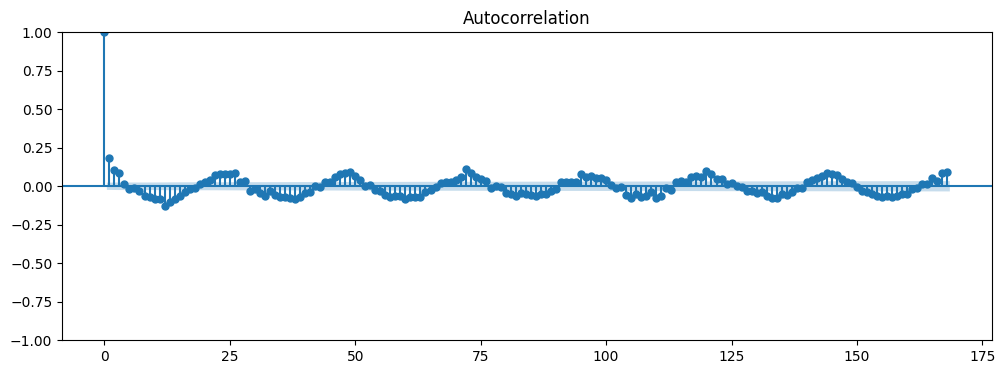

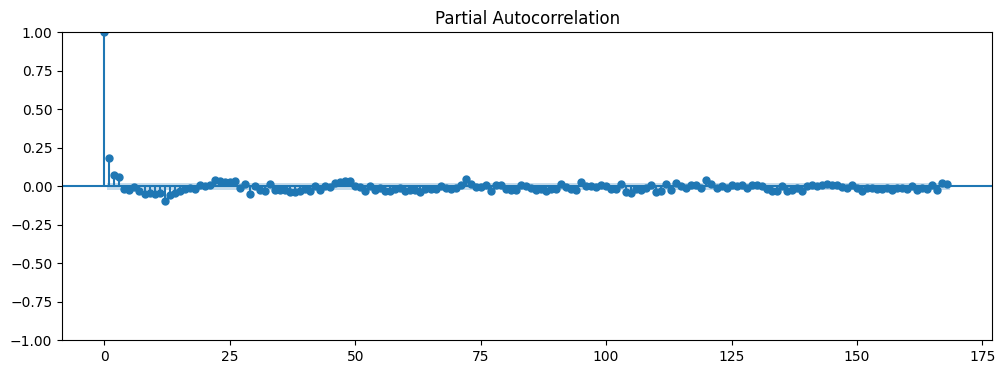

In [22]:
differenced_train = train_f.diff().dropna()
plot_acf(differenced_train, lags=24 * 7)
plot_pacf(differenced_train, lags=24 * 7, method='ywm')
plt.show()

In [23]:
from statsmodels.tsa.arima.model import ARIMA

model_arima = ARIMA(train_f, order=(2, 0, 1))
fit_arima = model_arima.fit()
forecast_arima = fit_arima.forecast(steps=5)
print(f"AIC for (2,0,1) : {fit_arima.aic}, BIC for (2,0,1): {fit_arima.bic}")

AIC for (2,0,1) : 19405.62802834856, BIC for (2,0,1): 19439.91560410452


### SARIMA(p,d,q) x (P,D,Q)$_s$
$$\phi(B)\Phi(B^s)(1-B)^d(1-B^s)^D y_t
=\theta(B)\Theta(B^s)\varepsilon_t.$$
Here $d,D$ control ordinary/seasonal differencing, $s$ is the seasonal period and $p,q,P,Q$ describe dependence in the differenced series.

### SARIMAX with exogenous predictors
In statsmodels, exogenous predictors give **regression with SARIMA errors**:
$$y_t=X_t^\top\beta+u_t,$$
$$\phi(B)\Phi(B^s)(1-B)^d(1-B^s)^D u_t
=\theta(B)\Theta(B^s)\varepsilon_t.$$
Future predictor values must be available or separately forecast. The example below supplies no exogenous predictors: it is SARIMA fitted through the SARIMAX interface.

The small illustrative daily-seasonal specification keeps classroom runtime manageable; these orders are not asserted to be optimal.

In [24]:
model_sarimax = SARIMAX(train_f, order=(1, 0, 0), seasonal_order=(1, 1, 0, 24))
fit_sarimax = model_sarimax.fit(disp=False, maxiter=100)
print('Converged:', fit_sarimax.mle_retvals['converged'])
forecast_sarimax = fit_sarimax.forecast(steps=len(test_observed))

Converged: True


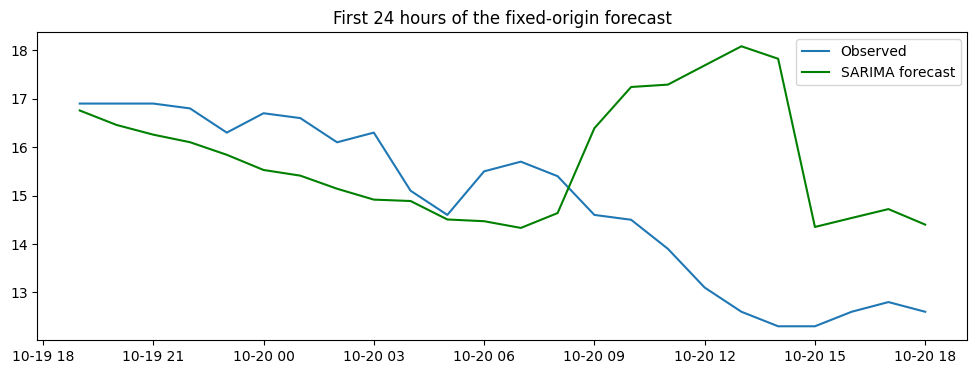

In [25]:
plt.figure(figsize=(12, 4))
plt.plot(test_observed.iloc[:24], label='Observed')
plt.plot(forecast_sarimax.iloc[:24], label='SARIMA forecast', color='green')
plt.title('First 24 hours of the fixed-origin forecast')
plt.legend()
plt.show()

# Evaluate

## Information criteria: AIC, AICc, BIC

**Purpose:** compare models fit on the same data by trading off fit vs. complexity.

### AIC (Akaike Information Criterion)

$$
\text{AIC} = -2 \ell(\hat{\theta}) + 2k
$$

Minimizes estimated out-of-sample Kullback–Leibler divergence. Tends to prefer slightly richer models.

---

### AICc (small-sample corrected AIC)

$$
\text{AICc} = \text{AIC} + \frac{2k(k+1)}{n - k - 1}
$$

Use when \( n/k \) isn’t large (common in ARIMA/SARIMA). Often a better default than plain AIC.

---

### BIC (Bayesian Information Criterion / Schwarz)

$$
\text{BIC} = -2 \ell(\hat{\theta}) + k \ln n
$$

Heavier penalty; asymptotically prefers the “true” model (if it’s in the candidate set). More conservative than AIC.

---

### How to use:

Compare within the same target series, sample, and likelihood. (Don’t compare AICs across different datasets.)

Smaller is better. Differences of \( \Delta \text{IC} \gtrsim 2 \) are meaningful; \( \Delta \text{IC} \gtrsim 10 \) is strong evidence.


Keep the differencing order fixed when comparing ARMA orders here. Likelihoods after different differencing transformations need not be comparable. Use chronological validation for forecasting choices, reserving the test period for final evaluation.

In [26]:
fit_sarimax.aic

21769.080175699175

In [27]:
orders = [(1, 0, 0), (2, 0, 0), (1, 0, 1), (2, 0, 1)]

for order in orders:
    model_arima = ARIMA(train_f, order=order)
    fit_arima = model_arima.fit()
    print(f"AIC for {order} : {fit_arima.aic}, BIC for {order}: {fit_arima.bic}")

AIC for (1, 0, 0) : 19703.99177367073, BIC for (1, 0, 0): 19724.564319124303


AIC for (2, 0, 0) : 19456.428631458522, BIC for (2, 0, 0): 19483.85869206329


AIC for (1, 0, 1) : 19490.433299223165, BIC for (1, 0, 1): 19517.863359827934


AIC for (2, 0, 1) : 19405.62802834856, BIC for (2, 0, 1): 19439.91560410452


In [28]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

actual = test_observed.loc[observed_mask]
predicted = forecast_sarimax.loc[observed_mask]
rmse_sarimax = np.sqrt(mean_squared_error(actual, predicted))
mae_sarimax = mean_absolute_error(actual, predicted)
print(f'RMSE: {rmse_sarimax:.3f}; MAE: {mae_sarimax:.3f} C')
print(f'Evaluated {len(actual)} observed targets; omitted {(~observed_mask).sum()} missing targets.')
print('Fixed-origin forecasts across the test horizon, not rolling one-step predictions.')

RMSE: 11.281; MAE: 8.984 C
Evaluated 1716 observed targets; omitted 41 missing targets.
Fixed-origin forecasts across the test horizon, not rolling one-step predictions.
